# Actividad 8 — Demostración reproducible en Google Colab

Esta demostración académica ejecuta pruebas y consulta evidencias versionadas del proyecto de observabilidad y MLOps para clasificación de sentimientos. Se distinguen los resultados históricos cargados desde archivos de evidencia de los resultados calculados durante esta ejecución. Las simulaciones controladas no representan producción.

## 1. Preparación del entorno

El repositorio se descarga desde GitHub y las dependencias se instalan desde `requirements.txt`. No se descargan datasets privados ni se utilizan rutas de Windows, credenciales o archivos externos al repositorio.

In [1]:
from pathlib import Path
import json
import os
import re
import subprocess
import sys

REPO_URL = "https://github.com/Papila9/actividad8-observabilidad-mlops.git"
REPO_DIR = Path("/content/actividad8-observabilidad-mlops")

if not REPO_DIR.exists():
    subprocess.run(["git", "clone", REPO_URL, str(REPO_DIR)], check=True)
os.chdir(REPO_DIR)

install = subprocess.run(
    [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
    text=True, capture_output=True
)
print(f"Repositorio: {REPO_DIR}")
print(f"Instalación de requirements.txt: código {install.returncode}")
if install.returncode != 0:
    print(install.stderr[-4000:])
else:
    print("Dependencias instaladas correctamente.")

Repositorio: /content/actividad8-observabilidad-mlops
Instalación de requirements.txt: código 0
Dependencias instaladas correctamente.


## 2. Pruebas automatizadas y compilación

Las cifras de pruebas se obtienen de la ejecución real de `unittest`; no se fija manualmente ningún total. La compilación valida los módulos publicados sin ejecutar las simulaciones que dependen del dataset original excluido.

In [2]:
from IPython.display import display

test_run = subprocess.run(
    [sys.executable, "-m", "unittest", "discover", "-s", "tests", "-v"],
    text=True, capture_output=True
)
test_output = test_run.stdout + "\n" + test_run.stderr
match = re.search(r"Ran\s+(\d+)\s+tests?", test_output)
failed_match = re.search(r"failures=(\d+), errors=(\d+)", test_output)
total_tests = int(match.group(1)) if match else None
failures = int(failed_match.group(1)) if failed_match else (0 if test_run.returncode == 0 else None)
errors = int(failed_match.group(2)) if failed_match else (0 if test_run.returncode == 0 else None)
summary = {"tests_ejecutadas": total_tests, "fallos": failures, "errores": errors, "codigo_salida": test_run.returncode}
display(summary)
print(test_output[-12000:])

compile_run = subprocess.run(
    [sys.executable, "-m", "compileall", "-q", "src", "scripts", "tests"],
    text=True, capture_output=True
)
print(f"Compilación Python: código {compile_run.returncode}")
if compile_run.stderr:
    print(compile_run.stderr)

{'tests_ejecutadas': 37, 'fallos': 0, 'errores': 0, 'codigo_salida': 0}


test_missing_required_column_is_rejected (actividad5.test_datos_prep.DataPreparationTests.test_missing_required_column_is_rejected) ... ok
test_output_hashes_and_dimensions_are_reproducible (actividad5.test_datos_prep.DataPreparationTests.test_output_hashes_and_dimensions_are_reproducible) ... ok
test_quality_and_duplicate_retention (actividad5.test_datos_prep.DataPreparationTests.test_quality_and_duplicate_retention) ... ok
test_run_persists_params_metrics_tags_and_artifacts (actividad5.test_mlflow_tracking.MlflowTrackingTests.test_run_persists_params_metrics_tags_and_artifacts) ... 2026/11/16 02:29:02 INFO mlflow.tracking.fluent: Experiment with name 'integration-test' does not exist. Creating a new experiment.
ok
test_audit_counts_repeated_and_conflicting_text_groups (actividad5.test_train.TrainingTests.test_audit_counts_repeated_and_conflicting_text_groups) ... ok
test_metrics_and_multiclass_roc_auc (actividad5.test_train.TrainingTests.test_metrics_and_multiclass_roc_auc) ... ok
t

## 3. Modelo estable y métricas supervisadas

Las métricas siguientes se cargan desde `evidencias/baseline/metricas_experimentos.json`. Son resultados históricos de una evaluación con etiquetas reales y partición documentada. No se recalculan aquí porque el dataset completo no se publica en GitHub.

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
import joblib

def load_json(relative_path):
    return json.loads(Path(relative_path).read_text(encoding="utf-8"))

historical = load_json("evidencias/baseline/metricas_experimentos.json")
stable_metrics = historical["models"]["logistic_regression"]["test_metrics"]
stable_table = pd.DataFrame([{
    "origen": "baseline histórico",
    "modelo": "logistic_regression",
    "accuracy": stable_metrics["accuracy"],
    "f1_macro": stable_metrics["f1_macro"],
    "observaciones_test": historical["protocol"]["test_rows"]
}])
display(stable_table)
print("SHA-256 histórico del dataset:", historical["data"]["sha256"])

stable_model = joblib.load("evidencias/modelos/logreg-stable-v1.pkl")
sample_texts = [
    "The flight was comfortable and the crew was helpful",
    "My baggage was lost and the response was very slow",
    "The service was acceptable but not exceptional"
]
predictions = stable_model.predict(sample_texts)
display(pd.DataFrame({"texto_de_ejemplo": sample_texts, "prediccion": predictions}))
print("Estas predicciones son una demostración de inferencia; no constituyen una evaluación supervisada.")

,origen,modelo,accuracy,f1_macro,observaciones_test
0,baseline histórico,logistic_regression,0.798156,0.7457,2928


SHA-256 histórico del dataset: 82539f706fdafc80f93dec7ae1cfc2310c179952f41548ed5c3ddf36effd67dd


,texto_de_ejemplo,prediccion
0,The flight was comfortable and the crew was he...,positive
1,My baggage was lost and the response was very ...,negative
2,The service was acceptable but not exceptional,negative


Estas predicciones son una demostración de inferencia; no constituyen una evaluación supervisada.


## 4. Observabilidad operativa y SLO

La tabla se construye desde la evidencia de monitorización y la simulación controlada de SLO. Latencia, disponibilidad, errores y volumen son SLI de inferencia. Accuracy y F1 requieren etiquetas reales; por eso aparecen como no disponibles en las ventanas sin etiquetas.

,ventana,availability,latency_mean_ms,latency_p95_ms,error_rate,prediction_volume,accuracy,f1_macro
0,before,1.0,5.105200,12.80356,0.0,3,None,None
1,during,1.0,606.372467,606.47074,0.0,3,None,None
2,after,1.0,2.384900,3.41962,0.0,3,None,None


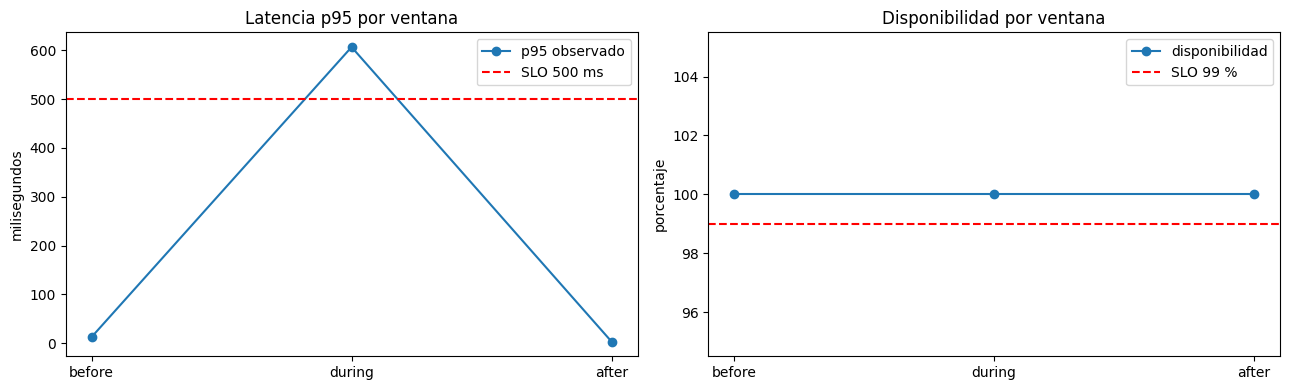

Estado de recuperación registrado: {'detected_in_window': 'during', 'recovered_in_window': True, 'slo_restored': True}
MLflow monitorización: 8215195010b94883b2b734c3d9cd7d56
MLflow SLO: 1c05aa318a0549bf98d881bfae4afe91


In [4]:
monitoring = load_json("evidencias/monitoring/exec-62ae1dd1c2bb.json")
slo = load_json("evidencias/slo/slo-simulation-0d1f16ed6596.json")

operational = pd.DataFrame([
    {"ventana": name, **window["slis"]}
    for name, window in slo["windows"].items()
])
display(operational)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(operational["ventana"], operational["latency_p95_ms"], marker="o", label="p95 observado")
axes[0].axhline(500, color="red", linestyle="--", label="SLO 500 ms")
axes[0].set_title("Latencia p95 por ventana")
axes[0].set_ylabel("milisegundos")
axes[0].legend()
axes[1].plot(operational["ventana"], operational["availability"] * 100, marker="o", label="disponibilidad")
axes[1].axhline(99, color="red", linestyle="--", label="SLO 99 %")
axes[1].set_title("Disponibilidad por ventana")
axes[1].set_ylabel("porcentaje")
axes[1].legend()
plt.tight_layout()
plt.show()

print("Estado de recuperación registrado:", slo["recovery"])
print("MLflow monitorización:", monitoring["mlflow_run_id"])
print("MLflow SLO:", slo["mlflow_run_id"])

## 5. Data drift y alertas

Se visualiza la calibración de 20 ventanas aleatorias y el escenario controlado de textos largos. JSD mide diferencias de frecuencias de tokens y KS la diferencia de longitudes. El drift detectado no se interpreta como pérdida de precisión sin etiquetas reales.

,window_id,seed,rows,token_jsd,length_ks
0,calibration-01,42,300,0.020631,0.033811
1,calibration-02,42,300,0.019525,0.025260
2,calibration-03,42,300,0.020426,0.037227
3,calibration-04,42,300,0.020182,0.078593
4,calibration-05,42,300,0.018264,0.061913
5,calibration-06,42,300,0.019765,0.046516
6,calibration-07,42,300,0.019823,0.054686
7,calibration-08,42,300,0.019835,0.032036
8,calibration-09,42,300,0.020488,0.024713
9,calibration-10,42,300,0.020273,0.090109


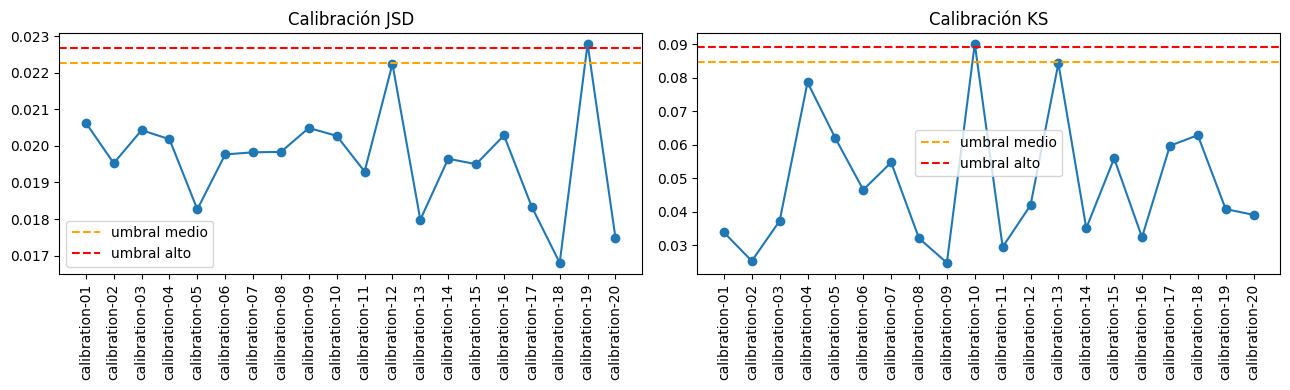

,escenario,token_jsd,length_ks,severidad,detecciones,alertas_emitidas
0,long_text_subset,0.156618,0.98,high,3,2


Model drift: {'status': 'unavailable_without_real_labels'}
MLflow drift: 362b5523d02c4cec8faf0c4633630963


In [5]:
calibration = load_json("evidencias/drift/calibracion_20_ventanas.json")
drift = load_json("evidencias/drift/drift-simulation-ca954b05123d.json")
calibration_table = pd.DataFrame(calibration["windows"])
display(calibration_table)

thresholds = calibration["recommended_thresholds"]
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
axes[0].plot(calibration_table["window_id"], calibration_table["token_jsd"], marker="o")
axes[0].axhline(thresholds["medium"]["token_jsd"], color="orange", linestyle="--", label="umbral medio")
axes[0].axhline(thresholds["high"]["token_jsd"], color="red", linestyle="--", label="umbral alto")
axes[0].set_title("Calibración JSD")
axes[0].tick_params(axis="x", rotation=90)
axes[0].legend()
axes[1].plot(calibration_table["window_id"], calibration_table["length_ks"], marker="o")
axes[1].axhline(thresholds["medium"]["length_ks"], color="orange", linestyle="--", label="umbral medio")
axes[1].axhline(thresholds["high"]["length_ks"], color="red", linestyle="--", label="umbral alto")
axes[1].set_title("Calibración KS")
axes[1].tick_params(axis="x", rotation=90)
axes[1].legend()
plt.tight_layout()
plt.show()

drift_result = drift["detection"]["data_drift"]
display(pd.DataFrame([{
    "escenario": drift["simulation"]["scenario"],
    "token_jsd": drift_result["token_jsd"],
    "length_ks": drift_result["length_ks"],
    "severidad": drift_result["severity"],
    "detecciones": drift["alert_stats"]["detections_generated"],
    "alertas_emitidas": drift["alert_stats"]["alerts_emitted"]
}]))
print("Model drift:", drift["detection"]["model_drift"])
print("MLflow drift:", drift["mlflow_run_id"])

## 6. Incidentes controlados y ciclo de vida del modelo

Las siguientes tablas consultan evidencias de incidentes, runbooks, reentrenamiento, rechazo de candidato y rollback. Los estados y acciones se presentan como simulaciones controladas, no como operación productiva.

In [6]:
incidents = load_json("evidencias/incidentes/incidents-simulation-ec32d80abd13.json")
incident_table = pd.DataFrame([{
    "incident_id": inc["incident_id"],
    "tipo": inc["incident_type"],
    "severidad": inc["severity"],
    "estado": inc["status"],
    "simulacion": inc["simulation"]["is_simulation"],
    "pasos_registrados": len(inc["lifecycle"])
} for inc in incidents["incidents"]])
display(incident_table)

lifecycle = load_json("evidencias/modelos/retraining-simulation-295e2bf4242c.json")
model_table = pd.DataFrame([
    {"version": item["version"], **item["evaluation"]["metrics"]}
    for item in [lifecycle["stable"], lifecycle["candidate"]]
])
display(model_table)
decision = lifecycle["acceptance_decision"]
display(pd.DataFrame([{
    "candidato_aceptado": decision["accepted"],
    "f1_drop_within_tolerance": decision["checks"]["f1_drop_within_tolerance"],
    "version_activa_despues": lifecycle["rollback_simulation"]["active_version_after"]
}]))
print("El candidato no fue promovido y el registro final conserva la versión estable.")
print("MLflow incidentes:", incidents["mlflow_run_id"])
print("MLflow ciclo de modelo:", lifecycle["mlflow_run_id"])

,incident_id,tipo,severidad,estado,simulacion,pasos_registrados
0,inc-503176ae6a5d,data_drift,high,open,True,2
1,inc-8af29a269c2c,slo_latency,critical,open,True,2


,version,accuracy,f1_macro
0,logreg-stable-v1,0.798156,0.745700
1,logreg-candidate-v2,0.773907,0.725802


,candidato_aceptado,f1_drop_within_tolerance,version_activa_despues
0,False,False,logreg-stable-v1


El candidato no fue promovido y el registro final conserva la versión estable.
MLflow incidentes: 0e69edec0ed24a669108561f269f2a52
MLflow ciclo de modelo: dd3260df7874492aa6ab5e183e9c45e7


## 7. Interpretación y conclusiones

- Las métricas de accuracy y F1 del modelo estable son resultados históricos supervisados; las predicciones de ejemplo no sustituyen esa evaluación.
- La simulación de latencia incumple el SLO durante la ventana `during` y registra recuperación posterior.
- El subconjunto de textos largos genera una alerta de data drift de severidad alta; esto no demuestra model drift ni pérdida de precisión.
- El candidato se rechaza por degradar F1 macro frente al modelo estable y el rollback conserva la versión estable.
- Para operar en producción se necesitarían tráfico real, etiquetas de calidad, servicio desplegado, almacenamiento de métricas en tiempo real y calibración con históricos operativos.

Esta conclusión se basa únicamente en los JSON y modelos publicados en el repositorio.